# Optimal sensor placement: QR pivoting on a POD basis

Compressed sensing asks *how many* random measurements suffice when all you
know is that the signal is sparse in a generic basis. In engineering we
usually know much more: we have **data**, so we can learn a tailored basis
$\boldsymbol{\Psi}_r$ in which the state is essentially $r$-dimensional. The
question then changes from *how many* to **where**. This notebook places
sensors with QR pivoting on a simulated wind-farm wake field with 2560 grid
points and compares them with randomly placed sensors.

**In this notebook you will**

* simulate a meandering wind-farm wake and learn its POD basis from training snapshots;
* choose sensor locations with one pivoted QR factorisation;
* reconstruct unseen snapshots from noisy point readings (gappy POD);
* compare QR and random sensors in error and in conditioning, for a growing number of sensors $m$.

**Before this notebook:** `osp_qr_illustrations`, which explains every matrix
and the QR pivoting step on a tiny example.

**Next:** this is the last notebook of the module.

**Runtime:** about 10 seconds (the $2560\times2560$ QR and the random-sensor
sweep take most of it).

### The model

$$\boldsymbol{x}\approx\bar{\boldsymbol{x}}+\boldsymbol{\Psi}_r\boldsymbol{a},\qquad
  \boldsymbol{y}=\mathbf{C}(\boldsymbol{x}-\bar{\boldsymbol{x}})=\boldsymbol{\Theta}\boldsymbol{a},\qquad
  \boldsymbol{\Theta}=\mathbf{C}\boldsymbol{\Psi}_r,\qquad
  \hat{\boldsymbol{a}}=\boldsymbol{\Theta}^{+}\boldsymbol{y},\qquad
  \hat{\boldsymbol{x}}=\bar{\boldsymbol{x}}+\boldsymbol{\Psi}_r\hat{\boldsymbol{a}} .$$

* $\boldsymbol{x}\in\mathbb{R}^{n}$: the wind speed at all $n=2560$ grid points;
  $\bar{\boldsymbol{x}}$ is its time average over the training data.
* $\boldsymbol{\Psi}_r\in\mathbb{R}^{n\times r}$: the POD basis, $r$ orthonormal spatial modes.
* $\boldsymbol{a}\in\mathbb{R}^{r}$: the modal coefficients (the unknowns).
* $\mathbf{C}\in\mathbb{R}^{m\times n}$: selects $m$ grid points (one 1 per row).
  In code, $\mathbf{C}\boldsymbol{x}$ is simply `x[sensors]`.
* $\boldsymbol{y}\in\mathbb{R}^{m}$: the sensor readings.
* $\boldsymbol{\Theta}^{+}$: the pseudo-inverse, i.e. least squares.

This is **gappy POD**. With sensor noise of variance $\eta^2$ the estimate
$\hat{\boldsymbol{a}}$ has covariance
$\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}$, so the error is
governed by how well conditioned $\boldsymbol{\Theta}$ is. The condition number
$\operatorname{cond}(\boldsymbol{\Theta})=\sigma_{\max}/\sigma_{\min}$ (ratio of
largest to smallest singular value) is the factor by which relative noise can
be amplified. Choosing the rows that make $\boldsymbol{\Theta}$ well
conditioned is a combinatorial problem, but the greedy maximum-volume choice
is exactly what **QR with column pivoting** on $\boldsymbol{\Psi}_r^{\top}$
computes, in one LAPACK call (Manohar et al., 2018).

## Setup

Standard imports. `pyutils` is the course helper package: `save_dual` writes
each figure in a light and a dark version to `../figures`. The generator
`rng` is seeded for reproducibility.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import qr
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(7)

## 1. A wake field to instrument

Three turbines of NREL-5MW scale (lengths in rotor diameters $D$): two side
by side at $x=D$ and one further downstream at $x=6D$. Each wake is a
Gaussian velocity deficit in the free-stream speed $U_0=10$ m/s that

* widens linearly downstream (rate `KWAKE`, initial width `W0`),
* recovers gradually behind the rotor (`recov`),
* **meanders** sideways at its own slow frequency (`yc`),
* and **breathes**: its strength oscillates slowly (`a`).

A weak travelling ripple is added on top. This is the usual low-order picture
of a wind-farm flow. The grid has $64\times40=2560$ points, and 600 snapshots
cover several meandering periods. Each snapshot is flattened into a row of
`snaps`, so `snaps` has shape (600, 2560): **rows are snapshots, columns are
grid points**. All turbine settings live in the `TURB` list.

In [2]:
NX, NY, NT = 64, 40, 600
D = 1.0
x = np.linspace(0.0, 12*D, NX)
y = np.linspace(-3*D, 3*D, NY)
XX, YY = np.meshgrid(x, y)                       # (NY, NX)
N = NX*NY
t = np.linspace(0, 200.0, NT)

TURB = [   # (x_pos, y_pos, deficit, meander amp, meander freq, breathe freq)
    (1.0*D, -1.3*D, 0.42, 0.30*D, 0.070, 0.031),
    (1.0*D,  1.4*D, 0.38, 0.26*D, 0.052, 0.043),
    (6.0*D,  0.0*D, 0.34, 0.34*D, 0.038, 0.026),
]
U0, KWAKE, W0 = 10.0, 0.075, 0.45*D

snaps = np.empty((NT, N))
for it, tt in enumerate(t):
    u = np.full_like(XX, U0)
    for (xp, yp, amp, ma, mf, bf) in TURB:
        down = XX - xp                           # distance downstream of this turbine
        active = down > 0                        # no wake upstream of the rotor
        w = W0 + KWAKE*np.maximum(down, 0.0)     # wake half-width grows downstream
        yc = yp + ma*np.sin(2*np.pi*mf*tt + xp)  # meandering wake centre
        recov = 1.0 - np.exp(-np.maximum(down, 0.0)/(2.5*D))
        a = amp*(1.0 + 0.18*np.sin(2*np.pi*bf*tt))   # breathing deficit strength
        u -= U0*a*active*recov*np.exp(-(YY - yc)**2/(2*w**2))*(W0/w)
    # weak shear + a travelling shedding ripple
    u += 0.25*np.sin(2*np.pi*(0.09*tt - XX/(4*D)))*np.exp(-(YY/(2.2*D))**2)
    snaps[it] = u.ravel()                        # row it = snapshot at time t[it]

print(f"snapshot matrix: {snaps.shape[0]} snapshots x {snaps.shape[1]} spatial points")

snapshot matrix: 600 snapshots x 2560 spatial points


The data set is a $600\times2560$ matrix: 600 snapshots of 2560 grid values.

## 2. POD basis from the training window

**Train/test split.** The basis is learned on the first 420 snapshots; the
remaining 180 are never used for training and all errors below are measured
on them.

**POD from the snapshot SVD.** Subtract the time-mean field
$\bar{\boldsymbol{x}}$ (`u_mean`) from every training snapshot and collect the
fluctuations in a snapshot matrix. Its thin SVD,
$\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$, gives orthonormal spatial
patterns ranked by the singular values $\sigma_1\ge\sigma_2\ge\dots$. The POD
basis $\boldsymbol{\Psi}_r$ consists of the first $r$ of these spatial
patterns; no other $r$-dimensional basis has a smaller average projection
error on the training snapshots. One detail of the code: here snapshots are
**rows**, so the spatial patterns are the **right** singular vectors, the
rows of `VT`. (If you store snapshots as columns, the same vectors appear as
the left singular vectors.)

**Choosing $r$.** The energy fraction kept by $r$ modes is
$E_r=\sum_{k\le r}\sigma_k^2/\sum_k\sigma_k^2$. We take the smallest $r$ with
$E_r\ge 0.99999$.

**Best possible error.** If we knew the full test field, the best we could do
with this basis is the orthogonal projection
$\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top(\boldsymbol{x}-\bar{\boldsymbol{x}})$.
Its relative error on the test window (`proj_err`) is the floor that no
sensor set can beat.

In [3]:
NTRAIN = 420
train, test = snaps[:NTRAIN], snaps[NTRAIN:]
u_mean = train.mean(0)                           # time-mean field from training data only
U_, sv, VT = np.linalg.svd(train - u_mean, full_matrices=False)
energy = np.cumsum(sv**2)/np.sum(sv**2)          # cumulative energy fraction E_r
R = int(np.searchsorted(energy, 0.99999) + 1)    # smallest r with E_r >= 0.99999
PSI = VT[:R].T                                   # (n, r), orthonormal columns
print(f"rank for 99.999% energy: r = {R}   (first 6 energy fractions: "
      f"{np.round(sv[:6]**2/np.sum(sv**2), 4)})")
print(f"cumulative energy at r: {energy[R-1]:.6f}")

Xt = test - u_mean                               # (ntest, n)
proj_err = np.linalg.norm(Xt - (Xt @ PSI) @ PSI.T)/np.linalg.norm(Xt)   # full-state projection error
print(f"best-possible (full-state projection) error on the test window: {proj_err:.3e}")
assert proj_err < 1e-2, "the field must be genuinely low-rank for this exercise"

rank for 99.999% energy: r = 13   (first 6 energy fractions: [0.309  0.1828 0.148  0.1099 0.0908 0.0824])
cumulative energy at r: 0.999995
best-possible (full-state projection) error on the test window: 2.181e-03


$r=13$ modes hold an energy fraction of 0.999995. The energy is spread over
several modes (the first six hold 0.309, 0.1828, 0.148, 0.1099, 0.0908 and
0.0824), because meandering moves the wakes sideways and that needs several
modes to describe. Still, the field is genuinely low-rank: projecting the
unseen test snapshots onto the 13 modes leaves a relative error of only
$2.181\times10^{-3}$. So 13 well-chosen numbers per snapshot should be enough.

## 3. Sensors: QR pivoting vs random

`scipy.linalg.qr(M, pivoting=True)` returns three things; the third is the
pivot order, a permutation of the columns of `M`. With
`M` $=\boldsymbol{\Psi}_r^\top$ each column is one grid point, and the pivoting
greedily picks, at each step, the grid point whose column has the largest part
not explained by the points already chosen. That grows
$|\det\boldsymbol{\Theta}|$ as fast as possible, one sensor at a time
(`osp_qr_illustrations` shows this step by step). The first $m$ pivots are
the sensor locations.

* For $m=r$ we pivot on $\boldsymbol{\Psi}_r^{\top}$ ($13\times2560$).
* For $m>r$, $\boldsymbol{\Psi}_r^{\top}$ has too few rows to rank more than
  $r$ points, so we pivot on $\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^{\top}$
  ($2560\times2560$), the standard extension. Its first $r$ pivots coincide
  with those of $\boldsymbol{\Psi}_r^{\top}$, because multiplying by
  $\boldsymbol{\Psi}_r$ (orthonormal columns) preserves lengths and angles.
  It also gives a nested ordering of all $n$ points, so the sets for
  increasing $m$ contain each other.

The cell times both factorisations and checks that the two orderings agree on
the first $r$ sensors.

In [4]:
t0 = time.perf_counter()
piv_exact = qr(PSI.T, pivoting=True)[2]                 # r pivots
piv_over = qr(PSI @ PSI.T, pivoting=True)[2]            # nested ordering, n pivots
t_qr = time.perf_counter() - t0
overlap = len(set(piv_exact[:R]) & set(piv_over[:R]))
print(f"QR pivoting for the whole sweep: {t_qr:.2f} s  "
      f"(exact and oversampled agree on {overlap}/{R} of the first r sensors)")


def qr_sensors(m):
    return np.sort(piv_exact[:R] if m == R else piv_over[:m])


NOISE = 0.02*train.std()                                # 2% measurement noise
print(f"measurement noise sigma = {NOISE:.4f} (2% of the field std)")

QR pivoting for the whole sweep: 0.91 s  (exact and oversampled agree on 13/13 of the first r sensors)
measurement noise sigma = 0.0181 (2% of the field std)


Both orderings agree on 13 of the 13 first sensors, as expected. The whole
placement costs one factorisation (its run time is printed above; the
$2560\times2560$ one dominates). Every reading will carry Gaussian noise with
standard deviation $\eta=0.0181$ m/s, which is 2% of the standard deviation of
the training field.

### Gappy POD error for many sensor sets

`reconstruct_error(sensors, noise_rng, sigma)` does gappy POD for the whole
test window at once:

1. $\boldsymbol{\Theta}$ = the rows of $\boldsymbol{\Psi}_r$ at the sensors ($m\times r$);
2. the readings $\mathbf{Y}$ ($m\times180$, one column per test snapshot) are the
   mean-removed test fields at the sensors plus noise of standard deviation $\eta$;
3. the least-squares coefficients
   $\hat{\mathbf{A}}=\arg\min\|\boldsymbol{\Theta}\mathbf{A}-\mathbf{Y}\|_F$ ($r\times180$);
4. it returns the relative error
   $\|\boldsymbol{\Psi}_r\hat{\mathbf{A}}-\mathbf{X}_{\text{test}}\|_F/\|\mathbf{X}_{\text{test}}\|_F$
   and $\operatorname{cond}(\boldsymbol{\Theta})$.

We then sweep the number of sensors $m$ over the values in `MS`, from $r=13$
up to $r+80=93$. For each $m$ we score the QR set and `NDRAW` = 200 random
sets (uniform without replacement over all grid points). The noise generator
is re-seeded with the same seed for every set, so all sets see the same noise
draw, and the comparison is fair. The table reports the QR error, the median
random error, their ratio ("gain"), and the same three numbers for the
condition number.

In [5]:
def reconstruct_error(sensors, noise_rng, sigma=None):
    """Gappy-POD reconstruction error over the whole held-out window."""
    sigma = NOISE if sigma is None else sigma
    Theta = PSI[sensors, :]                              # (m, r)
    Y = Xt[:, sensors].T + noise_rng.normal(0, sigma, (len(sensors), Xt.shape[0]))
    A = np.linalg.lstsq(Theta, Y, rcond=None)[0]         # (r, ntest)
    Xh = (PSI @ A).T
    return (np.linalg.norm(Xh - Xt)/np.linalg.norm(Xt),
            np.linalg.cond(Theta))


MS = np.array([R, R+2, R+5, R+10, R+20, R+35, R+55, R+80])
NDRAW = 200
err_qr, cond_qr = [], []
err_rand, cond_rand = [], []
for m in MS:
    e, c = reconstruct_error(qr_sensors(m), np.random.default_rng(11))
    err_qr.append(e); cond_qr.append(c)
    ee, cc = [], []
    for d in range(NDRAW):
        r_ = np.random.default_rng(5000 + 97*m + d)      # a reproducible seed per (m, draw)
        s = np.sort(r_.choice(N, m, replace=False))
        a, b = reconstruct_error(s, np.random.default_rng(11))
        ee.append(a); cc.append(b)
    err_rand.append(np.array(ee)); cond_rand.append(np.array(cc))

err_qr = np.array(err_qr); cond_qr = np.array(cond_qr)
err_rand = np.array(err_rand); cond_rand = np.array(cond_rand)   # shape (len(MS), NDRAW)
med_e = np.median(err_rand, 1); med_c = np.median(cond_rand, 1)

print(f"\n{'m':>4} {'QR err':>10} {'rand median':>12} {'gain':>7} "
      f"{'QR cond':>9} {'rand cond':>11} {'gain':>7}")
for i, m in enumerate(MS):
    print(f"{m:>4} {err_qr[i]:>10.4f} {med_e[i]:>12.4f} {med_e[i]/err_qr[i]:>6.1f}x "
          f"{cond_qr[i]:>9.1f} {med_c[i]:>11.1f} {med_c[i]/cond_qr[i]:>6.1f}x")


   m     QR err  rand median    gain   QR cond   rand cond    gain
  13     0.0610       4.2238   69.3x       3.3       660.5  202.6x
  15     0.0577       1.2744   22.1x       3.6       137.6   38.4x
  18     0.0524       0.2982    5.7x       3.5        30.9    8.7x
  23     0.0451       0.1199    2.7x       3.5        11.3    3.2x
  33     0.0364       0.0617    1.7x       3.0         5.4    1.8x
  48     0.0319       0.0417    1.3x       4.2         3.3    0.8x
  68     0.0311       0.0325    1.0x       5.3         2.7    0.5x
  93     0.0288       0.0263    0.9x       6.4         2.2    0.3x


Read the table row by row. At $m=r=13$ QR has error 0.0610 and condition
number 3.3, while the median random set has error 4.2238 (larger than the
field fluctuations themselves) and condition number 660.5: a gain of 69.3x in
error and 202.6x in conditioning. As $m$ grows, random sets improve quickly
and the gain shrinks: 5.7x at $m=18$, 1.7x at $m=33$, 1.0x at $m=68$. At the
largest budgets the random median is even slightly better (gain 0.9x at
$m=93$, error 0.0263 against 0.0288), and its condition number (2.2) is lower
than QR's (6.4): the nested $\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$ ordering
is greedy and not optimal for large $m$.

### The key claims, checked with asserts

The next cell prints a closer look at the tight case $m=r$ (percentiles and
the worst random draw), then asserts four claims:

* QR beats the random median by a solid factor in error and conditioning, and
  very few random draws beat it;
* with heavy oversampling the advantage collapses;
* random sensors need a much larger budget to match QR at $m=r$;
* without noise, $r$ QR point readings reach almost the full-state projection floor.

In [6]:
i0 = 0                                   # the tight case, m = r
print(f"\nAt m = r = {R} sensors:")
print(f"  QR      : error {err_qr[i0]:.4f}, cond(Theta) = {cond_qr[i0]:.1f}")
print(f"  random  : median error {med_e[i0]:.4f} "
      f"(90th pct {np.percentile(err_rand[i0], 90):.3f}), "
      f"median cond = {med_c[i0]:.1f} (90th pct {np.percentile(cond_rand[i0], 90):.0f})")
print(f"  -> QR is x{med_e[i0]/err_qr[i0]:.1f} more accurate and x{med_c[i0]/cond_qr[i0]:.1f} "
      f"better conditioned than the median random draw")
print(f"  fraction of random draws beating QR: "
      f"{np.mean(err_rand[i0] < err_qr[i0]):.3f}")
print(f"  worst random draw: error {err_rand[i0].max():.3f}, "
      f"cond {cond_rand[i0].max():.3e}")

assert med_e[i0]/err_qr[i0] > 3.0, "QR must beat the random median by a solid factor at m=r"
assert med_c[i0]/cond_qr[i0] > 5.0, "QR must be far better conditioned at m=r"
assert np.mean(err_rand[i0] < err_qr[i0]) < 0.05, "few random draws should beat QR"
# oversampling closes the gap - the honest caveat
gain_last = med_e[-1]/err_qr[-1]
print(f"\nAt m = {MS[-1]} sensors random sensors are just as good "
      f"(gain x{gain_last:.1f}): oversampling is the poor man's optimisation")
assert gain_last < 0.1*med_e[i0]/err_qr[i0], "the QR advantage must collapse with oversampling"
# QR at m=r must beat random at a larger budget: sensors well placed buy sensors saved
j_match = int(np.argmax(med_e <= err_qr[i0]))            # first budget where the random median matches QR at m = r
print(f"random sensors need m = {MS[j_match]} to match QR's accuracy at m = {R} "
      f"-> {MS[j_match]/R:.1f}x the hardware")
assert MS[j_match] > R
# without measurement noise, QR sensors alone already reach the projection optimum:
# the 6% error above is bought entirely by the 2% sensor noise, not by the placement
err_qr_clean, _ = reconstruct_error(qr_sensors(R), np.random.default_rng(11), sigma=0.0)
print(f"  noise-free QR reconstruction: {err_qr_clean:.2e} vs projection floor "
      f"{proj_err:.2e} -> r point measurements are as good as the full state")
assert err_qr_clean < 5*proj_err
assert err_qr[i0] < 0.10, "with 2% sensor noise QR must still stay within a few percent"


At m = r = 13 sensors:
  QR      : error 0.0610, cond(Theta) = 3.3
  random  : median error 4.2238 (90th pct 827.453), median cond = 660.5 (90th pct 17491269014733)
  -> QR is x69.3 more accurate and x202.6 better conditioned than the median random draw
  fraction of random draws beating QR: 0.000
  worst random draw: error 3885290495367.752, cond 3.214e+16

At m = 93 sensors random sensors are just as good (gain x0.9): oversampling is the poor man's optimisation
random sensors need m = 48 to match QR's accuracy at m = 13 -> 3.7x the hardware
  noise-free QR reconstruction: 2.89e-03 vs projection floor 2.18e-03 -> r point measurements are as good as the full state


All asserts pass. At $m=r$ none of the 200 random draws beats QR (fraction
0.000). The random results have a very heavy tail: the 90th percentile error is
827.453 and the worst draw is numerically singular (condition number
$3.214\times10^{16}$), so random placement can fail completely, not just be
mediocre. Random sensors need $m=48$ to match QR's accuracy at $m=13$, which
is 3.7x the hardware. Without noise, the 13 QR readings give error
$2.89\times10^{-3}$, close to the projection floor of $2.18\times10^{-3}$: the
0.0610 error with noise comes from the 2% sensor noise, not from the placement.

## 4. Pictures

For the figures we fix the QR set and **one** random set (the first random
draw used at $m=r$), take one held-out snapshot (test snapshot 60), and
reconstruct it from noisy readings at each set with `recon_field`. The
printed numbers are the relative errors for this single snapshot. The first
figure then summarises the whole sweep.

single held-out snapshot with 13 sensors: QR 0.0026, this random draw 0.3142


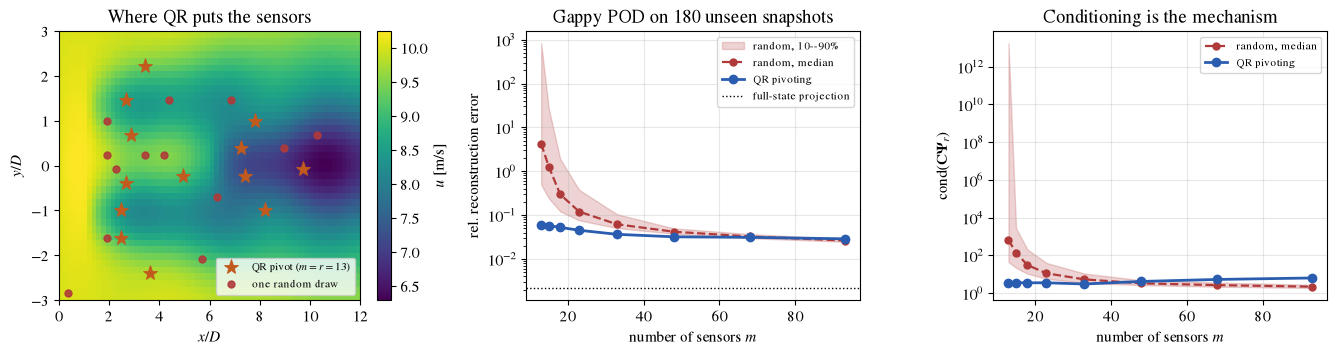

In [7]:
S_QR = qr_sensors(R)
S_RAND = np.sort(np.random.default_rng(5000 + 97*R + 0).choice(N, R, replace=False))
snap_show = test[60]
field_true = snap_show.reshape(NY, NX)


def recon_field(sensors):
    Theta = PSI[sensors, :]
    yv = (snap_show - u_mean)[sensors] + np.random.default_rng(3).normal(0, NOISE, len(sensors))
    a = np.linalg.lstsq(Theta, yv, rcond=None)[0]
    return (u_mean + PSI @ a).reshape(NY, NX)          # add the mean back, unflatten to the grid


f_qr, f_rand = recon_field(S_QR), recon_field(S_RAND)
e_qr_1 = np.linalg.norm(f_qr - field_true)/np.linalg.norm(field_true)
e_rand_1 = np.linalg.norm(f_rand - field_true)/np.linalg.norm(field_true)
print(f"single held-out snapshot with {R} sensors: QR {e_qr_1:.4f}, "
      f"this random draw {e_rand_1:.4f}")


def plot_placement():
    fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
    ext = [x[0], x[-1], y[0], y[-1]]
    im = ax[0].imshow(field_true, origin='lower', extent=ext, aspect='auto',
                      cmap='viridis')
    ax[0].plot(x[S_QR % NX], y[S_QR//NX], '*', color='C1', ms=11, mew=0.6,   # flat index -> (column, row)
               label=f'QR pivot ($m=r={R}$)')
    ax[0].plot(x[S_RAND % NX], y[S_RAND//NX], 'o', color='C3', ms=5, alpha=0.9,
               label='one random draw')
    ax[0].set(xlabel='$x/D$', ylabel='$y/D$',
              title='Where QR puts the sensors')
    ax[0].legend(fontsize=8, loc='lower right')
    ax[0].grid(False)
    fig.colorbar(im, ax=ax[0], fraction=0.046, label='$u$ [m/s]')

    lo = np.percentile(err_rand, 10, axis=1); hi = np.percentile(err_rand, 90, axis=1)
    ax[1].fill_between(MS, lo, hi, color='C3', alpha=0.22, label='random, 10--90%')
    ax[1].semilogy(MS, med_e, 'o--', color='C3', lw=1.6, ms=5, label='random, median')
    ax[1].semilogy(MS, err_qr, 'o-', color='C0', lw=2.0, ms=6, label='QR pivoting')
    ax[1].axhline(proj_err, color=fg(), ls=':', lw=1.0, label='full-state projection')
    ax[1].set(xlabel='number of sensors $m$', ylabel='rel. reconstruction error',
              title=f'Gappy POD on {test.shape[0]} unseen snapshots')
    ax[1].legend(fontsize=8)

    lo = np.percentile(cond_rand, 10, axis=1); hi = np.percentile(cond_rand, 90, axis=1)
    ax[2].fill_between(MS, lo, hi, color='C3', alpha=0.22)
    ax[2].semilogy(MS, med_c, 'o--', color='C3', lw=1.6, ms=5, label='random, median')
    ax[2].semilogy(MS, cond_qr, 'o-', color='C0', lw=2.0, ms=6, label='QR pivoting')
    ax[2].set(xlabel='number of sensors $m$',
              ylabel='$\\mathrm{cond}(\\mathbf{C}\\boldsymbol{\\Psi}_r)$',
              title='Conditioning is the mechanism')
    ax[2].legend(fontsize=8)
    plt.tight_layout()


save_dual(plot_placement, 'cs_placement', FIG)
plt.show()

**How to read this figure.** Left panel: the held-out snapshot of the wind
speed $u$ in m/s (colour bar; yellow is fast free stream, dark purple is slow
wake), with $x/D$ downstream and $y/D$ across. The wind blows from left to
right; the two upstream wakes start near $x/D=1$ and the third turbine sits at
$x/D=6$. Orange stars are the 13 QR sensors, red dots the 13 sensors of one
random draw. Middle panel: relative reconstruction error over the 180 unseen
snapshots (log scale) against the number of sensors $m$. Blue solid line: QR.
Red dashed line: median of the 200 random sets, with the shaded band from the
10th to the 90th percentile. The dotted black line is the full-state
projection floor. Right panel: the same layout for
$\operatorname{cond}(\mathbf{C}\boldsymbol{\Psi}_r)$.

**What it shows.** QR does not spread sensors uniformly. All 13 stars sit in
the wake region, where the meandering and breathing change the field, and
none in the uniform inflow on the left, which carries no information about
the modes. The random draw wastes some sensors there. In the middle
panel QR stays flat between 0.0610 and 0.0288, while the random median starts
at 4.2238 and its 90th percentile at $m=13$ is 827.453: the band shoots up
because some random sets are almost singular. The random median first
reaches QR's $m=13$ accuracy at $m=48$ and meets the QR curve at $m=68$. The right panel shows why: the condition number of QR stays between
3.0 and 6.4, while the random median starts at 660.5. Error follows
conditioning. Neither method reaches the dotted floor, because the 2% sensor
noise sets the error level once $\boldsymbol{\Theta}$ is well conditioned.

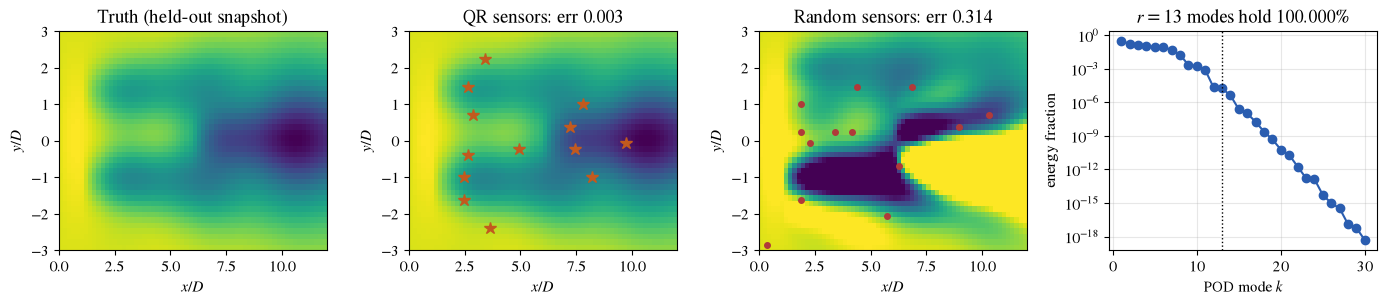

In [8]:
def plot_placement_field():
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
    ext = [x[0], x[-1], y[0], y[-1]]
    vmin, vmax = field_true.min(), field_true.max()       # same colour limits for all three fields
    for a, f, ttl in ((ax[0], field_true, 'Truth (held-out snapshot)'),
                      (ax[1], f_qr, f'QR sensors: err {e_qr_1:.3f}'),
                      (ax[2], f_rand, f'Random sensors: err {e_rand_1:.3f}')):
        a.imshow(f, origin='lower', extent=ext, aspect='auto', cmap='viridis',
                 vmin=vmin, vmax=vmax)
        a.set(xlabel='$x/D$', ylabel='$y/D$', title=ttl)
        a.grid(False)
    ax[1].plot(x[S_QR % NX], y[S_QR//NX], '*', color='C1', ms=9)
    ax[2].plot(x[S_RAND % NX], y[S_RAND//NX], 'o', color='C3', ms=4)
    ax[3].semilogy(np.arange(1, 31), sv[:30]**2/np.sum(sv**2), 'o-', color='C0', lw=1.5)
    ax[3].axvline(R, color=fg(), ls=':', lw=1.0)
    ax[3].set(xlabel='POD mode $k$', ylabel='energy fraction',
              title=f'$r={R}$ modes hold {100*energy[R-1]:.3f}%')
    plt.tight_layout()


save_dual(plot_placement_field, 'cs_placement_field', FIG)
plt.show()

**How to read this figure.** The first three panels share axes ($x/D$, $y/D$)
and one colour scale (the range of the true field), so colours can be
compared directly. Panel 1: the true held-out snapshot. Panel 2: its gappy POD
reconstruction from the 13 QR sensors (orange stars), with noisy readings.
Panel 3: the reconstruction from 13 random sensors (red dots) with the same
kind of noise. The titles give the relative error for this snapshot. Panel 4:
the energy fraction $\sigma_k^2/\sum_j\sigma_j^2$ of the first 30 POD modes
on a log scale; the dotted line marks $r=13$. Its title shows the cumulative
energy 0.999995 rounded to three decimals as a percentage.

**What it shows.** With QR sensors the reconstruction is visually identical
to the truth (error 0.0026). The random draw gives 0.3142: large regions are
saturated at the ends of the colour scale and the wake structure is lost,
even though it uses exactly as many sensors with the same noise level. The
spectrum explains why 13 sensors can be enough at all: the energy fractions
drop by many orders of magnitude after the first dozen modes, so the field
really is about 13-dimensional.

## Summary

* With a learned basis the question stops being *how many* random samples and
  becomes **which** $m$ locations. The answer is a single pivoted QR on
  $\boldsymbol{\Psi}_r^{\top}$.
* QR sensors sit where the modes differ most, inside the meandering wake
  region, not uniformly and not in the uniform inflow.
* At the tight budget $m=r=13$ the payoff is large (error 0.0610 against a
  random median of 4.2238) and the mechanism is conditioning:
  $\operatorname{cond}(\mathbf{C}\boldsymbol{\Psi}_r)$ is 3.3 for QR and 660.5
  for the median random draw. A bad random draw is catastrophic, not merely
  mediocre.
* Oversampling narrows the gap: random sensors need $m=48$ to match QR at
  $m=13$, and at $m=93$ they are as good. If sensors are cheap, use more of
  them. If they are expensive, place them. That trade is the practical content
  of optimal sensor placement, and it is what makes a digital twin observable
  from a handful of instruments.

## Try this

This notebook has no single parameter cell; the settings sit where they are
used.

1. **Noise level.** In section 3, change `NOISE = 0.02*train.std()` to `0.0`
   or `0.1*train.std()`. How do the QR and random errors at $m=r$ change? (The
   asserts assume 2% noise and may fail.)
2. **Energy threshold.** In section 2, replace `0.99999` in the line that sets
   `R` by `0.999` or `0.9999`. How many modes and sensors does that give, and
   how does the projection floor move?
3. **Training window.** Change `NTRAIN = 420` to 200. Is the basis still good
   enough for the unseen snapshots?
4. **Uniform grid of sensors.** Build a regular set such as
   `np.arange(0, N, N // R)[:R]` and score it with
   `reconstruct_error(..., np.random.default_rng(11))`. Where does it fall
   between QR and random?